# Zimbabwe droughts and maize: 2015/16 and 2023/24 (solved)
### From a drought indicator to food availability, trade and prices

**Author**: Ignacio Saldivia Gonzatti (Wageningen University & Research)

## About

This notebook was developed for Module 8, *Advanced use of climate data and C3S tools*, of the [*Understanding Climate Data*](https://climate.copernicus.eu/online-course-understanding-climate-data) online course of the Copernicus Climate Change Service (C3S). It is the practical exercise of the section on using C3S data to assess the impact of drought on maize availability.

**Data sources**
- **Drought indicator**: SPEI-6 from the C3S dataset [Drought indicators derived from reanalysis](https://cds.climate.copernicus.eu/datasets/derived-drought-historical-monthly), Climate Data Store (CDS).
- **Crop production and trade**: [FAOSTAT](https://www.fao.org/faostat/) bulk downloads of the Food and Agriculture Organization of the United Nations (FAO).
- **Market prices**: [FEWS NET Data Warehouse](https://fdw.fews.net/) of the Famine Early Warning Systems Network.
- **Country boundaries**: [Natural Earth](https://www.naturalearthdata.com/) (public domain).

## Running this notebook

This is the **solved version** of the notebook: all the code has already been run, so you can read the outputs (figures, tables and printed results) without running anything.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/isaldiviagonzatti/2027-c3s-climate-data-m8/blob/main/zimbabwe_drought_maize_food_security_solved.ipynb)

To run the notebook yourself, open the [original version](https://colab.research.google.com/github/isaldiviagonzatti/2027-c3s-climate-data-m8/blob/main/zimbabwe_drought_maize_food_security.ipynb) in Google Colab. To keep your own changes, use **File > Save a copy in Drive** once the notebook is open in Colab.

## Introduction

This notebook uses C3S drought data, FAOSTAT crop and trade statistics, and
FEWS NET market prices. We compare two droughts with different maize impacts,
then look more closely at trade and prices during the 2024 event.

### Learning objectives

By the end of this notebook, you will be able to:

- retrieve gridded climate data from the Climate Data Store (CDS);
- mask and aggregate gridded data over a country;
- download and reshape FAOSTAT bulk data;
- combine climate, crop, trade, and market-price records; and
- distinguish a year-to-year change from a detrended anomaly.

### Before you start: get access to the data

The drought data are downloaded from the Copernicus [Climate Data Store (CDS)](https://cds.climate.copernicus.eu). You need:

1. A free ECMWF account. Register or log in at the [Climate Data Store (CDS)](https://cds.climate.copernicus.eu).
2. To accept the licence of the dataset [Drought indicators derived from reanalysis](https://cds.climate.copernicus.eu/datasets/derived-drought-historical-monthly). Open the dataset page, go to the **Download** tab and accept the terms of use at the bottom of the page. You only need to do this once.
3. Your **personal access token**. You can find it on your profile page once you are logged in (see the [API how-to page](https://cds.climate.copernicus.eu/how-to-api)).

The other data sources (FAOSTAT, FEWS NET and Natural Earth) are public and do not need an account.

The notebook will ask you to paste your token when it needs it. The token is not shown on screen and is not saved in the notebook.

---
## 1. Prepare the environment

This notebook uses:
- `cdsapi` to download the drought data from the CDS
- `xarray` and `netCDF4` to work with the gridded climate data
- `geopandas` and `regionmask` to select the area of Zimbabwe
- `pandas`, `numpy` and `scipy` to process and analyse the data
- `requests` to download the FAOSTAT, FEWS NET and boundary files
- `matplotlib` to plot the results

Google Colab already includes most of these packages. Run the cell below to install the missing ones. This may take a minute.

Downloaded files are kept in a `data/` folder, so later runs in the same session are faster.

In [1]:
%pip install -q cdsapi regionmask netCDF4

### We import the required libraries and set up the notebook environment.

In [2]:
# The comments explain what the libraries are used for.
# we ignore the warning by IProgress (used by cdsapi)
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")


import os  # Read CDS credentials supplied through environment variables.
from getpass import getpass  # Request a CDS token without displaying it.
from pathlib import Path  # Create portable paths for downloaded data.
from zipfile import ZipFile  # Read ZIP archives returned by CDS and FAOSTAT.

import cdsapi  # Request climate data from the Copernicus Climate Data Store.
import geopandas as gpd  # Read and plot a geographic boundary.
import matplotlib.pyplot as plt  # Create the notebook figures.
import numpy as np  # Calculate weights, trends, and numerical summaries.
import pandas as pd  # Clean, reshape, and combine tabular data.
import regionmask  # Mask the data grid to Zimbabwe's boundary.
import requests  # Download public FAOSTAT, FEWS NET, and boundary files.
import xarray as xr  # Open and process gridded NetCDF climate data.
from scipy.stats import linregress  # Calculate linear trends in the data.

### Download helper

In [3]:
# We create a folder to store the downloaded data.
# The folder is created only if it does not already exist

DATA = Path("data")
DATA.mkdir(parents=True, exist_ok=True)

# we define function to skip already downloaded files 
# and return the local path of the file

def download(url, path, params=None):
    """Download a file once and return its local path."""
    path = Path(path)
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        response = requests.get(url, params=params, timeout=180)
        response.raise_for_status()
        path.write_bytes(response.content)
    return path

## 2. Retrieve drought data from C3S

The SPEI index is a widely used drought indicator that combines precipitation and potential evapotranspiration. It is standardized, so it can be compared across regions and seasons.

Negative SPEI values indicate dry conditions. Values below -1.5 are considered "very dry," and values below -2.0 are considered "extremely dry." 

We use March **SPEI-6**, which summarizes the water balance over the preceding
six months, covering the austral summer growing season of Zimbabwe.

The request covers every
March from 1991 to 2024, covering the 2015/16 and 2023/24 droughts. The 34 years of data contextualise the two events, and allow us to calculate a long-term trend if desired.

In [4]:
# Connect securely to the CDS
# The function looks for a local `.cdsapirc` file, then for a `CDSAPI_KEY` 
# environment variable. If neither is available, it will 
# ask for the personal access token through a hidden input.

CDS_URL = "https://cds.climate.copernicus.eu/api"

def connect_to_cds():
    """Create a CDS client without storing a token in the notebook."""
    if (Path.home() / ".cdsapirc").exists():
        return cdsapi.Client()

    key = os.environ.get("CDSAPI_KEY")
    if key:
        url = os.environ.get("CDSAPI_URL", CDS_URL)
        return cdsapi.Client(url=url, key=key)

    key = getpass("Enter your CDS personal access token: ")
    return cdsapi.Client(url=CDS_URL, key=key)

In [5]:
# Depending on the area size and the number of years, the download may take a few minutes.

dataset = "derived-drought-historical-monthly"
request = {
    "variable": ["standardised_precipitation_evapotranspiration_index"],
    "accumulation_period": ["6"],
    "version": "1_0",
    "product_type": ["reanalysis"],
    "dataset_type": "consolidated_dataset",
    "year": [str(year) for year in range(1991, 2025)],
    "month": ["03"],
    "area": [-15, 25, -23, 34],  # north, west, south, east
}

spei_zip = DATA / "spei_march_1991_2024.zip"
if not spei_zip.exists():
    cds_client = connect_to_cds()
    cds_client.retrieve(dataset, request, str(spei_zip))

2026-11-21 19:41:37,960 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
2026-11-21 19:41:40,623 INFO Request ID is 83e7ddbb-2b7d-4a56-9156-7fb7616b62c3
2026-11-21 19:41:40,937 INFO status has been updated to successful


The CDS response contains one NetCDF file per year. We open the files, select
the SPEI variable, and concatenate them along the time dimension.

In [6]:
spei_folder = DATA / "spei_march_1991_2024"

# we first unzip the downloaded file
if not spei_folder.exists():
    with ZipFile(spei_zip) as archive:
        archive.extractall(spei_folder)

# we now concatenate the SPEI files into a single xarray dataset
fields = []
for path in sorted(spei_folder.glob("*.nc")):
    with xr.open_dataset(path) as source:
        field = source["SPEI6"].rename({"lat": "latitude", "lon": "longitude"})
        fields.append(field.load())
spei = xr.concat(fields, dim="time").sortby("time")

# we can verify that the dataset has the expected number of time steps 
# and that there are no duplicate time steps
assert spei.time.size == (2024 - 1991 + 1)
assert not spei.get_index("time").duplicated().any()
spei

<xarray.DataArray 'SPEI6' (time: 34, latitude: 33, longitude: 37)> Size: 332kB
array([[[-0.83015298, -0.92858501, -1.06088803, ..., -0.94107515,
         -1.04385704, -0.79881026],
        [-0.82604435, -0.95215092, -1.10086693, ..., -0.87866781,
         -0.88983027, -0.84373375],
        [-0.85238935, -0.88677407, -1.01618474, ..., -0.82937991,
         -0.81416493, -0.84247121],
        ...,
        [ 0.31208213,  0.1407323 ,  0.1380571 , ...,  0.08102757,
          0.26386832,  0.2021689 ],
        [ 0.24686011,  0.17686096,  0.19387579, ...,  0.02677519,
          0.11010847,  0.10708028],
        [ 0.23813099,  0.21260576,  0.18981575, ..., -0.01916459,
          0.08898287,  0.15023929]],

       [[-1.29062067, -1.37311369, -1.38981582, ..., -2.07849929,
         -1.87789356, -1.96028533],
        [-1.33418331, -1.39835038, -1.40427389, ..., -1.9615826 ,
         -2.02006587, -1.92533902],
        [-1.25961651, -1.39517648, -1.41187757, ..., -1.88569475,
         -1.99356792, -1.90533197],
...
        [ 0.68314597,  0.59741961,  0.53197785, ...,  1.73332974,
          1.19940393,  1.12055302],
        [ 0.84602409,  0.7232765 ,  0.56611058, ...,  1.81075961,
          1.49381855,  1.45336697],
        [ 0.99053006,  0.90886825,  0.71539637, ...,  1.98472237,
          2.04667516,  2.15702734]],

       [[-2.33272462, -2.45782734, -2.32048231, ..., -1.5492543 ,
         -1.47524582, -0.90029781],
        [-2.37585047, -2.40716924, -2.25097036, ..., -1.15207664,
         -1.47899774, -1.17337723],
        [-2.38640223, -2.30300012, -2.14646217, ..., -1.26107789,
         -1.3743447 , -1.28501863],
        ...,
        [-3.39407722, -3.16028465, -2.63860569, ..., -0.25886085,
         -0.32620812, -0.46934215],
        [-3.37291754, -3.36239853, -3.17739421, ..., -0.16344945,
         -0.24161949, -0.34205568],
        [-3.23680787, -3.22704366, -3.14724136, ..., -0.15896305,
         -0.26885127, -0.34495019]]], shape=(34, 33, 37))
Coordinates:
  * time       (time) datetime64[ns] 272B 1991-03-01T06:00:00 ... 2024-03-01T...
  * latitude   (latitude) float64 264B -15.0 -15.25 -15.5 ... -22.5 -22.75 -23.0
  * longitude  (longitude) float64 296B 25.0 25.25 25.5 ... 33.5 33.75 34.0
Attributes:
    long_name:  Standardized Drought Index (SPEI6)

### Aggregate SPEI over Zimbabwe

We download a country boundary, mask grid-cell centres outside Zimbabwe, and
calculate a latitude-weighted national mean.

In [7]:
# Natural Earth offers a free, public domain dataset of country boundaries. 

boundary_url = (
    "https://naturalearth.s3.amazonaws.com/110m_cultural/"
    "ne_110m_admin_0_countries.zip"
)
boundary_zip = download(boundary_url, DATA / "natural_earth_countries.zip")
countries = gpd.read_file(f"zip://{boundary_zip.resolve()}")

print(countries.head())
print(100 * "-")
print("We search for Zimbabwe in the country boundaries dataset:")
print(countries[countries["ADMIN"].str.contains("zimbabwe", case=False, na=False)])

        featurecla  scalerank  LABELRANK                   SOVEREIGNT SOV_A3  \
0  Admin-0 country          1          6                         Fiji    FJI   
1  Admin-0 country          1          3  United Republic of Tanzania    TZA   
2  Admin-0 country          1          7               Western Sahara    SAH   
3  Admin-0 country          1          2                       Canada    CAN   
4  Admin-0 country          1          2     United States of America    US1   
   ADM0_DIF  LEVEL               TYPE TLC                        ADMIN  ...  \
0         0      2  Sovereign country   1                         Fiji  ...   
1         0      2  Sovereign country   1  United Republic of Tanzania  ...   
2         0      2      Indeterminate   1               Western Sahara  ...   
3         0      2  Sovereign country   1                       Canada  ...   
4         1      2            Country   1     United States of America  ...   
      FCLASS_TR     FCLASS_ID     FCLASS_PL FC

In [8]:
# we can filter by any column that identifies the region of interest
# let's use SOV_A3
zimbabwe = countries.loc[countries["SOV_A3"] == "ZWE"].to_crs(4326)

# NOTE: if you see the error "ValueError: zero-size array to reduction operation 
# fmin which has no identity", check that you are using the correct country code. 

# we can now mask the data over the region 
# and calculate the average using weights based on latitude 
# to account for the fact that gridcell size varies with latitude

mask = regionmask.mask_geopandas(zimbabwe, spei.longitude, spei.latitude).notnull()
spei_zimbabwe = spei.where(mask)
weights = np.cos(np.deg2rad(spei.latitude))
aggregated_spei = spei_zimbabwe.weighted(weights).mean(["latitude", "longitude"])

# we save the aggregated SPEI values in a pandas DataFrame for easier analysis
climate = pd.DataFrame({
    "year": aggregated_spei.time.dt.year.values,
    "spei": aggregated_spei.values,
}).set_index("year")
print(climate.head())
print(100 * "-")
print("\nThe two years we are interested in are 2016 and 2024:")
climate.loc[[2016, 2024]]

          spei
year          
1991 -0.762238
1992 -1.819189
1993  0.255432
1994 -0.588964
1995 -1.326258
----------------------------------------------------------------------------------------------------
The two years we are interested in are 2016 and 2024:


,spei
year,
2016,-1.337472
2024,-1.605149


### Let's now see how the aggregated SPEI values have changed over time.

Values outside the -1 to 1 range indicate drought or wet conditions, respectively.

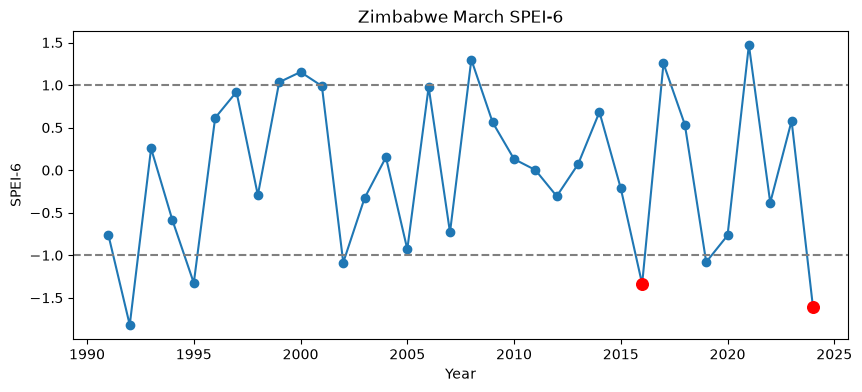

In [9]:
ax = climate.spei.plot(figsize=(10, 4), marker="o")
ax.axhline(-1, color="grey", linestyle="--")
ax.axhline(1, color="grey", linestyle="--")
ax.scatter([2016, 2024], climate.loc[[2016, 2024], "spei"], s=70, color="red", zorder=5)
ax.set(title="Zimbabwe March SPEI-6", ylabel="SPEI-6", xlabel="Year")
plt.show()

The drought conditions in 2016 and 2024 are clearly visible in the plot, together with the 
severe drought of 1992.

We can now do a visual inspection of the SPEI values for the two drought years, and compare them to a normal season, like 2014/15 (just before the 2015/16 drought).

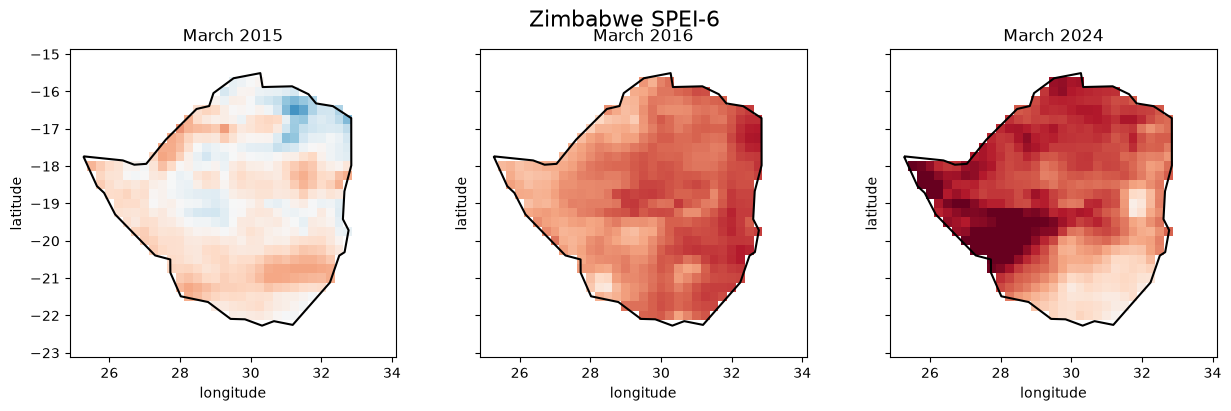

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
fig.suptitle("Zimbabwe SPEI-6", fontsize=16)
for ax, year in zip(axes, [2015, 2016, 2024]):
    spei_zimbabwe.sel(time=f"{year}-03").squeeze().plot(
        ax=ax, cmap="RdBu", vmin=-2.5, vmax=2.5, add_colorbar=False
    )
    zimbabwe.boundary.plot(ax=ax, color="black")
    ax.set_title(f"March {year}")
    ax.set_xlabel("longitude")
    ax.set_ylabel("latitude")
plt.show()

We can also verify the area of the country under drought conditions.

In [11]:
# check the area of the country under drought conditions for each of the three years
for year in [2015, 2016, 2024]:
    drought_area = (spei_zimbabwe.sel(time=f"{year}-03") < -1).sum().item()
    total_area = spei_zimbabwe.sel(time=f"{year}-03").count().item()
    percentage_drought = (drought_area / total_area) * 100
    print(f"Year {year}: {percentage_drought:.2f}% of the area under drought conditions.")

Year 2015: 0.97% of the area under drought conditions.
Year 2016: 82.91% of the area under drought conditions.
Year 2024: 80.58% of the area under drought conditions.


## 3. Retrieve maize production data from FAOSTAT

Now that we know the years with severe drought, we can look at how maize production was affected. We use FAOSTAT's bulk data download, which contains production and trade statistics for all crops and countries.

FAOSTAT's crop-production archive is large, so we read it in chunks and keep
only Zimbabwe. This also gives us harvested area for other crops.

In [12]:
qcl_url = (
    "https://bulks-faostat.fao.org/production/"
    "Production_Crops_Livestock_E_All_Data_(Normalized).zip"
)
qcl_zip = download(qcl_url, DATA / "faostat_crop_production.zip")

# we unzip and read the CSV file in chunks, keeping only the rows for Zimbabwe.
with ZipFile(qcl_zip) as archive:
    csv_name = next(name for name in archive.namelist() if "Normalized" in name)
    chunks = []
    with archive.open(csv_name) as source:
        for chunk in pd.read_csv(
            source, encoding="utf-8-sig", chunksize=200_000, low_memory=False
        ):
            rows = chunk.loc[chunk["Area"] == "Zimbabwe"]
            if not rows.empty:
                chunks.append(rows)

qcl = pd.concat(chunks, ignore_index=True)
qcl[["Item", "Element", "Year", "Unit", "Value"]][qcl["Item"].str.contains("maize", case=False, na=False)]

,Item,Element,Year,Unit,Value
5966,Green corn (maize),Area harvested,1961,ha,NaN
5967,Green corn (maize),Area harvested,1962,ha,NaN
5968,Green corn (maize),Area harvested,1963,ha,NaN
5969,Green corn (maize),Area harvested,1964,ha,NaN
5970,Green corn (maize),Area harvested,1965,ha,NaN
...,...,...,...,...,...
9974,Oil of maize,Production,2019,t,14839.75
9975,Oil of maize,Production,2020,t,13929.73
9976,Oil of maize,Production,2021,t,13354.97
9977,Oil of maize,Production,2022,t,13022.25


### Let's compare yield, production, and harvested area

In [13]:
# you see above that "maize" appears in many different items
# here we care about the grain (primary product)

# FAO data comes as a long table with one row per year, item, and element
# we can pivot the table to have one row per year and one column per element
# (area harvested, yield, and production)
maize = qcl.loc[
    (qcl["Item"] == "Maize (corn)")
    & qcl["Element"].isin(["Area harvested", "Yield", "Production"])
].pivot(index="Year", columns="Element", values="Value")

maize = maize.rename(columns={
    "Area harvested": "area_ha",
    "Yield": "yield_kg_ha",
    "Production": "production_t",
})
# we convert yield from kg/ha to t/ha
maize["yield_t_ha"] = maize["yield_kg_ha"] / 1000


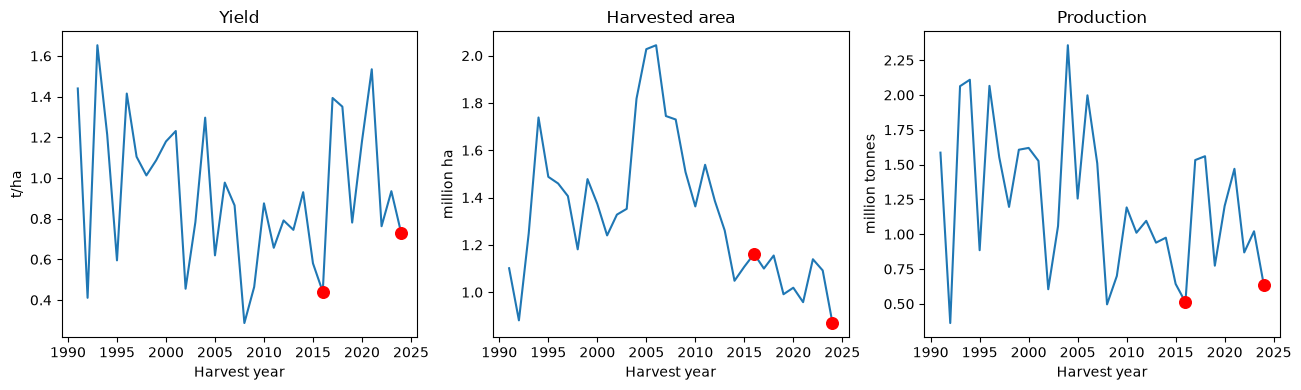

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
maize.loc[1991:, "yield_t_ha"].plot(ax=axes[0], title="Yield")
maize.loc[1991:, "area_ha"].div(1e6).plot(ax=axes[1], title="Harvested area")
maize.loc[1991:, "production_t"].div(1e6).plot(ax=axes[2], title="Production")
#plot 2015/16 and 2024 as red dots
for year in [2016, 2024]:
    axes[0].scatter(year, maize.loc[year, "yield_t_ha"], color="red", s=70, zorder=5)
    axes[1].scatter(year, maize.loc[year, "area_ha"] / 1e6, color="red", s=70, zorder=5)
    axes[2].scatter(year, maize.loc[year, "production_t"] / 1e6, color="red", s=70, zorder=5)
axes[0].set_ylabel("t/ha")
axes[1].set_ylabel("million ha")
axes[2].set_ylabel("million tonnes")
for ax in axes:
    ax.set_xlabel("Harvest year")
plt.tight_layout()
plt.show()

From the plots, we can describe a few things:
(Remember: production = yield * harvested area)
- Yield decreased in both drought years from the previous year
- After the 2015/16 drought, yield increased and has never been as low as in 2015/16. 
- Yield in 2023/24 is almost double the yield in 2015/16
- Harvested area increased in 2015/16 from its previous year, but decreased sharply in 2023/24. 
- The production in both drought years is similar, and below average.

We can see that production can be the same in two drought years, but the underlying causes are different. In 2015/16, the low production was due to low yield, while in 2023/24, it was also due to low harvested area.

We can now verify this numerically:

In [15]:
maize["yield_change_pct"] = maize.yield_t_ha.pct_change() * 100
maize["area_change_pct"] = maize.area_ha.pct_change() * 100
maize["production_change_pct"] = maize.production_t.pct_change() * 100
maize_mean_yield = maize.loc[1991:2024, "yield_t_ha"].mean()

columns = [
    "yield_t_ha",
    "yield_change_pct", "area_change_pct", "production_change_pct",
]

print(maize.loc[[2016, 2024], columns].round(2))
print(f"\nAverage yield for 1991-2024: {maize_mean_yield:.2f} t/ha")

Element  yield_t_ha  yield_change_pct  area_change_pct  production_change_pct
Year                                                                         
2016           0.44            -24.09             4.90                 -20.38
2024           0.73            -21.94           -20.37                 -37.83
Average yield for 1991-2024: 0.93 t/ha


We can now verify that:

- The yield in 2023/24 is higher but less than double the yield in 2015/16
- The yield change from the previous year is similar in both drought years
- The production decrease in 2023/24 is almost double the production decrease in 2015/16 and is caused by both a decrease in yield and a decrease in harvested area.

If we check the definition of harvested area on FAOSTAT, we read that _"Data refer to the area from which a crop is gathered. Area harvested, therefore, excludes the area from which, although sown or planted, there was no harvest due to damage, failure, etc..."_

We can therefore hypothesize that at least part of the harvested area decrease in 2023/24 is due to crop failure, and therefore the relatively high yield in 2023/24 is due to the fact that only the surviving fields were reported. This is called a "survivorship bias" and is a common problem in agricultural statistics.

This is supported by [this USDA FAS report](https://apps.fas.usda.gov/newgainapi/api/Report/DownloadReportByFileName?fileName=Grain+and+Feed+Annual_Pretoria_Zimbabwe_RH2024-0002.pdf). Table 1 shows that from the 1778 planted area, only 870 was harvested, which is almost half. (Note that their marketing year 2024/25 corresponds to our 2023/24 season.)

### Did maize area switch to other crops?

Let's do a check and compare maize area with the sum for other primary crops to see if perhaps maize area was switched to other crops. 

In [16]:
area = qcl.loc[qcl["Element"] == "Area harvested"].copy()
# we remove aggregate crop groups to limit double counting
area = area.loc[~area["Item Code (CPC)"].fillna("").astype(str).str.startswith("'F")]
area_by_crop = area.pivot(index="Item", columns="Year", values="Value")

area_summary = pd.DataFrame(index=[2014, 2015, 2023, 2024])
area_summary["all crops (million ha)"] = area_by_crop.sum().reindex(area_summary.index) / 1e6
area_summary["maize (million ha)"] = area_by_crop.loc["Maize (corn)"].reindex(area_summary.index) / 1e6
area_summary["other crops (million ha)"] = (
    area_summary["all crops (million ha)"] - area_summary["maize (million ha)"]
)
area_summary["maize share (%)"] = (
    100 * area_summary["maize (million ha)"] / area_summary["all crops (million ha)"]
)
area_summary.round(2)

,all crops (million ha),maize (million ha),other crops (million ha),maize share (%)
2014,2.31,1.05,1.27,45.29
2015,2.27,1.11,1.16,48.81
2023,2.82,1.09,1.72,38.78
2024,2.23,0.87,1.36,39.00


In [17]:
pd.DataFrame({
    "2014 to 2015 (%)": area_summary.loc[2015] / area_summary.loc[2014] * 100 - 100,
    "2023 to 2024 (%)": area_summary.loc[2024] / area_summary.loc[2023] * 100 - 100,
}).round(1)

,2014 to 2015 (%),2023 to 2024 (%)
all crops (million ha),-1.9,-20.8
maize (million ha),5.7,-20.4
other crops (million ha),-8.2,-21.1
maize share (%),7.8,0.6


Other crop area fell by a similar percentage in 2024, while maize's share was
almost unchanged. It does not appear that maize area was switched to other crops, and it also shows that other crops also reduced their area, much more than in 2015/16.

### Is there a correlation between SPEI and maize yield/production?

We can calculate a simple correlation between the SPEI and maize yield and production. We first detrend (remove the long-term trend) the yield and production data so that increases in yield and production over time do not bias the correlation.

<Axes: title={'center': 'Yield residuals'}, xlabel='Year'>

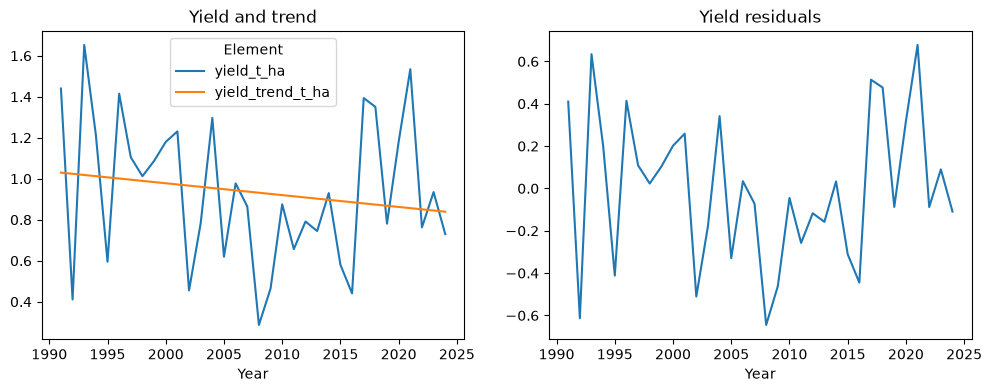

In [18]:
# we fit the long-term yield trend
yield_years = maize.loc[1991:2024, "yield_t_ha"].dropna()

yield_slope, yield_intercept = np.polyfit(
    yield_years.index,
    yield_years,
    1,
)

# we calculate the yield level expected in each year according to the fitted line
maize["yield_trend_t_ha"] = (
    yield_intercept + yield_slope * maize.index
)

# then calculate the difference between observed and expected yield
maize["yield_residual_t_ha"] = (
    maize["yield_t_ha"] - maize["yield_trend_t_ha"]
)

# quick visualization of the yield trend and residuals
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
maize.loc[1991:2024, ["yield_t_ha", "yield_trend_t_ha"]].plot(ax=axes[0], title="Yield and trend")
maize.loc[1991:2024, "yield_residual_t_ha"].plot(ax=axes[1], title="Yield residuals")   

In [19]:
# we can now calculate the correlation between the SPEI and the yield residuals
correlation_data = climate.join(
    maize[["yield_residual_t_ha"]],
    how="inner",
).dropna()

correlation_result = linregress(
    correlation_data["spei"],
    correlation_data["yield_residual_t_ha"],
)

pd.Series({
    "R_squared": correlation_result.rvalue**2,
    "p_value": correlation_result.pvalue,
}).round(3)

R_squared    0.221
p_value      0.005
dtype: float64

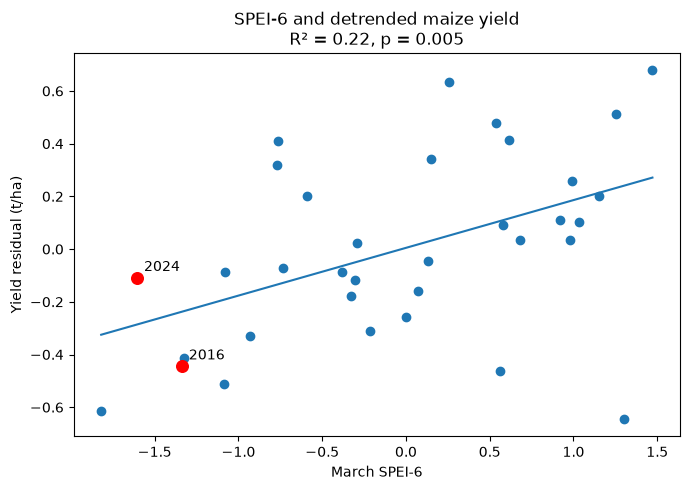

In [20]:
# and we plot the correlation

x = correlation_data["spei"]
y = correlation_data["yield_residual_t_ha"]

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x, y)

# we add the regression line to the scatter plot
x_line = np.linspace(x.min(), x.max(), 100)
y_line = correlation_result.intercept + correlation_result.slope * x_line
ax.plot(x_line, y_line)

# We can highlight and label the two drought events.
for year in [2016, 2024]:
    x_value = correlation_data.loc[year, "spei"]
    y_value = correlation_data.loc[year, "yield_residual_t_ha"]

    ax.scatter(x_value, y_value, color="red", s=70, zorder=5)
    ax.annotate(
        str(year),
        (x_value, y_value),
        xytext=(5, 5),
        textcoords="offset points",
    )

ax.set_title(
    "SPEI-6 and detrended maize yield\n"
    f"R² = {correlation_result.rvalue**2:.2f}, "
    f"p = {correlation_result.pvalue:.3f}"
)
ax.set_xlabel("March SPEI-6")
ax.set_ylabel("Yield residual (t/ha)")

plt.tight_layout()
plt.show()

We can see that:

- There is a moderate positive correlation between March SPEI-6 and detrended maize yield: drier seasons generally have yields farther below the long-term trend.
- In this simple linear model, SPEI-6 is associated with about 22% of the observed variation in detrended yield.

However:

- The relationship is not deterministic. The 2016 and 2024 points show that droughts of similar severity can have different yield outcomes.
- As we saw, reported harvested area may affect reported yield if severely damaged fields are excluded from harvested area.
- Maize yield is also influenced by rainfall timing, temperature, agricultural inputs, crop varieties, management, pests, and other factors.
- This is an exploratory association and does not establish causality.

## 4. How did trade respond to the drought events that affected maize production?

We can use FAOSTAT's trade data to see how the reduction in domestic maize production affected imports and exports.

In [21]:
# we take the trade data from the smaller Africa archive, which is updated through 2024
trade_url = (
    "https://bulks-faostat.fao.org/production/"
    "Trade_CropsLivestock_E_Africa.zip"
)
trade_zip = download(trade_url, DATA / "faostat_trade_africa.zip")
with (
    ZipFile(trade_zip) as archive,
    archive.open("Trade_CropsLivestock_E_Africa.csv") as source,
):
    trade_wide = pd.read_csv(source, encoding="latin-1", low_memory=False)

trade_rows = trade_wide.loc[
    (trade_wide["Area"] == "Zimbabwe")
    & (trade_wide["Item"] == "Maize (corn)")
    & trade_wide["Element"].isin(["Import quantity", "Export quantity"])
]
# we use melt to reshape the data from wide to long format
trade = trade_rows.melt(
    id_vars="Element",
    value_vars=[f"Y{year}" for year in range(2015, 2025)],
    var_name="year",
    value_name="tonnes",
)
# we now pivot the table to have one row per year and one column per element 
# (Import quantity, Export quantity)
trade["year"] = trade.year.str[1:].astype(int)
trade = trade.pivot(index="year", columns="Element", values="tonnes")
trade = trade.rename(columns={"Import quantity": "imports_t", "Export quantity": "exports_t"})
trade = trade.join(maize.production_t)

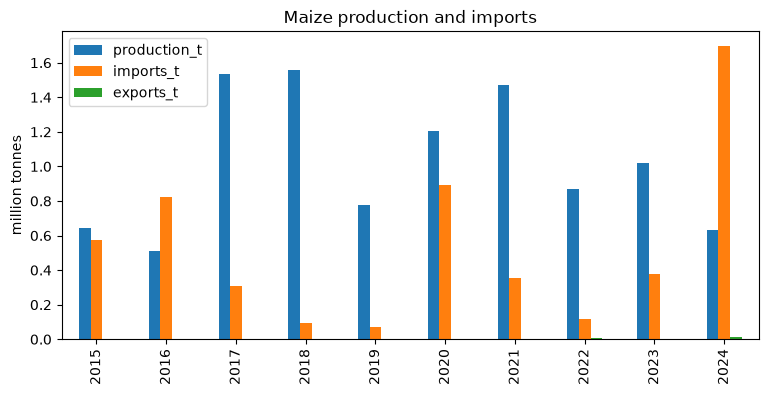

In [22]:
trade[["production_t", "imports_t", "exports_t"]].div(1e6).plot.bar(figsize=(9, 4))
plt.ylabel("million tonnes")
plt.xlabel("")
plt.title("Maize production and imports")
plt.show()

From the figure, we can see that:

- Imports rose sharply in 2024, and were around double the imports in 2016, which makes sense as they had to compensate for a larger absolute production loss.
- Exports are relatively small and insignificant compared to imports and production. 

(Note that stocks, feed, and losses are not included in this simple calculation, so the total is not a full food balance.)

## 5. And what happened to maize prices?

FEWS NET collects market prices for different commodities across the world. We can access local maize prices for Zimbabwe, and compare them to the drought events. Here we focus on the 2023/24 drought, since price data for 2015/16 is scarce in the FEWS NET database.

In [23]:
catalog_path = download(
    "https://fdw.fews.net/api/marketproduct/",
    DATA / "fews_market_products.json",
    params={
        "format": "json",
        "country": "Zimbabwe",
        "product": "Maize Grain (White)",
    },
)

catalog = pd.read_json(catalog_path)

# There are many variables to filter the catalog
# You can explore the online catalog to see the available values
catalog[[
    "price_type",
    "product_source",
    "data_usage_policy",
    "data_source_organization",
    "currency",
    "unit",
]].drop_duplicates()

,price_type,product_source,data_usage_policy,data_source_organization,currency,unit
0,Retail,Local,Public,FEWS NET,USD,17.5 kg
1,Retail,Local,Public,FEWS NET,USD,20_L
9,Retail,Local,Public,FEWS NET,ZAR,17.5 kg
18,Retail,Local,Public,FEWS NET,ZWL,kg
19,Retail,Local,Public,FEWS NET,USD,kg
40,Retail,Local,Public,"WFP, Zimbabwe",USD,kg


In [24]:
# And then filter according to your needs. 
# We'll keep only USD prices, in 20 L and 17.5 kg units
series = catalog.loc[
    (catalog["currency"] == "USD")
    & catalog["unit"].isin(["20_L", "17.5 kg"])
    & (pd.to_datetime(catalog["last_period_date"]) >= "2021-01-01")
].copy()

print(series.groupby(["currency", "unit"]).agg(
    series=("id", "size"),
    markets=("fnid", "nunique"),
))
print(100 * "-")
print(series.head())

                  series  markets
currency unit                    
USD      17.5 kg      17       17
         20_L         21       21
----------------------------------------------------------------------------------------------------
        id                                               name   country  \
0  6972269  Bindura, Chipadze market (Open market), Zimbab...  Zimbabwe   
1  6635968  Bindura, Chipadze market (Open market), Zimbab...  Zimbabwe   
2  6635993  Bulawayo, Renkini market (Open market), Zimbab...  Zimbabwe   
3  6972286  Bulawayo, Renkini market (Open market), Zimbab...  Zimbabwe   
4  6654736  Chegutu, Gomba market (Open market), Zimbabwe ...  Zimbabwe   
    fewsnet_region geographic_group        fnid  \
0  Southern Africa  Southern Africa  ZW0000M064   
1  Southern Africa  Southern Africa  ZW0000M064   
2  Southern Africa  Southern Africa  ZW0000M069   
3  Southern Africa  Southern Africa  ZW0000M069   
4  Southern Africa  Southern Africa  ZW0000M070   
       

In [25]:
# Now that we identified the available markets and series, 
# we can download the price data for each using the IDs

price_params = [
    ("dataseries", series_id)
    for series_id in series["id"]
]

price_params += [
    ("format", "csv"),
    ("fields", "simple"),
    ("start_date", "2021-01-01"),
    ("end_date", "2024-12-31"),
]

prices_path = download(
    "https://fdw.fews.net/api/marketpricefacts/",
    DATA / "fews_maize_grain_usd.csv",
    params=price_params,
)

prices = pd.read_csv(prices_path, encoding="utf-8-sig")
print(prices.columns)
print(100 * "-")
print(prices.head())


Index(['geographic_group', 'fewsnet_region', 'country', 'admin_1', 'admin_2',
       'market', 'cpcv2', 'product', 'price_type', 'product_source',
       'collection_schedule', 'start_date', 'period_date', 'value',
       'availability', 'availability_description', 'value_one_month_ago',
       'value_one_year_ago', 'two_year_average', 'five_year_average',
       'pct_change_from_one_month_ago', 'pct_change_from_one_year_ago',
       'pct_change_from_two_year_average', 'pct_change_from_five_year_average',
       'currency', 'unit', 'unit_type', 'common_unit', 'common_currency',
       'exchange_rate', 'common_unit_price', 'common_currency_price', 'status',
       'collection_status', 'data_usage_policy', 'source_document', 'id',
       'dataseries_name', 'longitude', 'latitude', 'is_staple_food'],
      dtype='str')
----------------------------------------------------------------------------------------------------
  geographic_group   fewsnet_region   country              admin_1  \
0

In [26]:
# we do some filtering to keep only the relevant data
prices = prices.loc[
     (prices["status"] == "Aggregated")
    & (prices["collection_status"] == "Published")
].copy()

prices["month"] = (
    pd.to_datetime(prices["period_date"])
    .dt.to_period("M")
    .dt.to_timestamp()
)

# We only keep markets with observations before the drought season and during 2024.
coverage = prices.groupby("market")["month"].agg(
    first_month="min",
    last_month="max",
)
comparison_markets = coverage.index[
    (coverage["first_month"] < "2023-10-01")
    & (coverage["last_month"] >= "2024-01-01")
]
prices = prices.loc[prices["market"].isin(comparison_markets)].copy()

# FEWS NET treats the 20 L maize bucket as approximately 17.5 kg
prices["kg_per_unit"] = prices["unit"].map({
    "17.5 kg": 17.5,
    "20_L": 17.5,
})

prices["price_usd_kg"] = prices["value"] / prices["kg_per_unit"]

coverage.loc[comparison_markets]

,first_month,last_month
market,,
"Bindura, Chipadze market (Open market)",2021-07-01,2024-12-01
"Bulawayo, Renkini market (Open market)",2021-07-01,2024-12-01
"Chegutu, Gomba market (Open market)",2021-07-01,2024-12-01
"Chinhoyi, Gadzema market (Open market)",2021-07-01,2024-12-01
"Gokwe South, Gokwe Produce market (Open market)",2021-07-01,2024-12-01
"Gutu, Mupandawana market (Open market)",2021-07-01,2024-12-01
"Gweru, Mutapa market (Open market)",2021-07-01,2024-12-01
"Harare, Mbare market (Open market)",2021-07-01,2024-12-01
"Hwange, Number 1 terminus market (Open market)",2021-07-01,2024-12-01


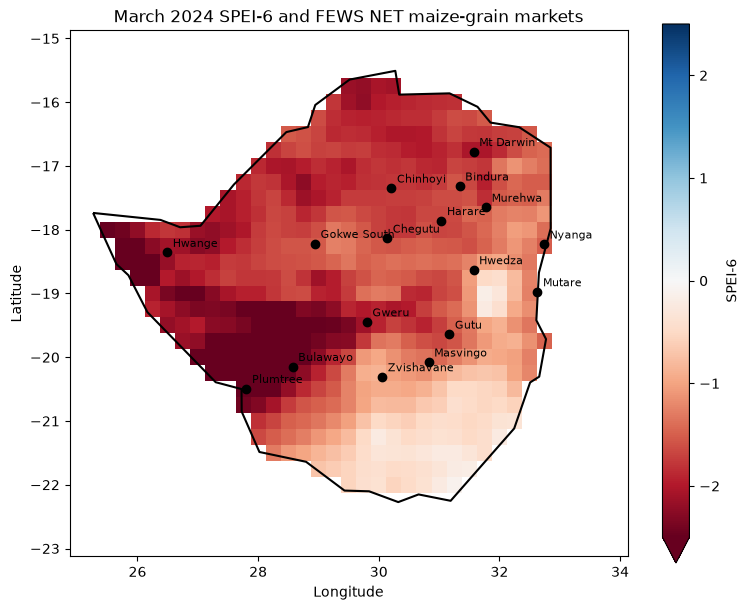

In [27]:
# We can see where these markets are located in Zimbabwe
markets = prices[
    ["market", "longitude", "latitude"]
].drop_duplicates()

fig, ax = plt.subplots(figsize=(9, 7))
spei_zimbabwe.sel(time="2024-03").squeeze().plot(
    ax=ax,
    cmap="RdBu",
    vmin=-2.5,
    vmax=2.5,
    cbar_kwargs={"label": "SPEI-6"},
)
zimbabwe.boundary.plot(ax=ax, color="black")
ax.scatter(markets["longitude"], markets["latitude"], color="black")

for _, market in markets.iterrows():
    # extract city name before comma
    label = market["market"].split(",")[0]
    ax.annotate(
        label,
        (market["longitude"], market["latitude"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8,
    )

ax.set(
    title="March 2024 SPEI-6 and FEWS NET maize-grain markets",
    xlabel="Longitude",
    ylabel="Latitude",
)
plt.show()

We can now calculate the median price across all markets for each month, 
and check if markets with lower SPEI values (drier conditions) had higher price increases. 


In [28]:
# we calculate the median price and number of markets for each month
monthly_prices = prices.groupby("month").agg(
    median_price_usd_kg=("price_usd_kg", "median"),
    markets=("market", "nunique"),
)

monthly_prices.tail()

,median_price_usd_kg,markets
month,,
2024-06-01,0.514286,17
2024-07-01,0.514286,17
2024-08-01,0.514286,17
2024-09-01,0.514286,17
2024-12-01,0.571429,17


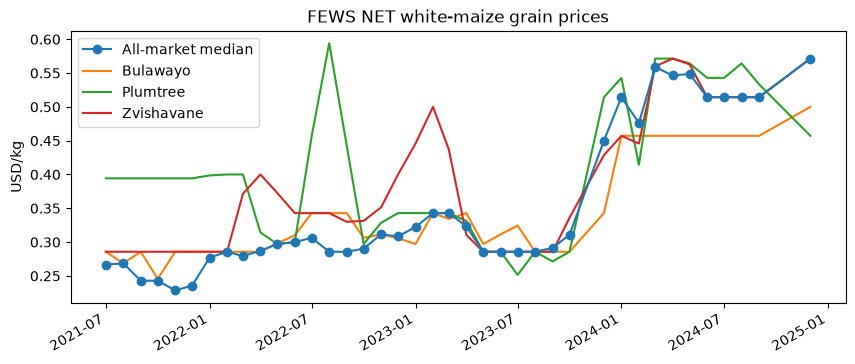

In [29]:
# We select two markets where SPEI was particularly low in 2024
# and one market where SPEI was relatively normal
representative_markets = ["Bulawayo", "Plumtree", "Zvishavane"]

market_prices = (
    prices.assign(city=prices["market"].str.split(",").str[0])
    .loc[lambda data: data["city"].isin(representative_markets)]
    .groupby(["month", "city"])["price_usd_kg"]
    .median()
    .unstack()
)

ax = monthly_prices["median_price_usd_kg"].plot(
    figsize=(10, 4),
    marker="o",
    label="All-market median",
)
market_prices.plot(ax=ax, zorder=-1)

plt.title("FEWS NET white-maize grain prices")
plt.xlabel("")
plt.ylabel("USD/kg")
plt.legend()
plt.show()

From the figure we can see that:
 - The median prices spiked at the end of 2023 and remained high through 2024, which is consistent with the drought and production loss.
 - Bulawayo, a market where SPEI was lower than the national average, did not have a higher price than the median. Similarly, Zvishavane, a market where SPEI was relatively normal, had a price increase similar to the median. 
 - This suggests that we need to look at other factors to explain the price increase. We already saw that drought does not fully explain the yield decrease. Moreover, other factors such as trade, market access, and storage may also play a role in price formation in the different markets.

## Take-home messages

- The 2015/16 and 2023/24 seasons had similarly severe national March SPEI-6.
- Yield fell strongly from 2023 to 2024, although its level was closer to the
  long-term trend than in 2016.
- In 2024, lower yield and a smaller reported harvested area combined to reduce
  maize production. Other crop area also fell, so crop switching is not the main
  pattern in the FAOSTAT data.
- Maize imports and observed USD maize-grain prices increased during the recent event.

These indicators describe connected parts of the food system. They do not by
themselves establish causality or measure household food insecurity.